[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/09-system-design/03_caching.ipynb)

*System Design · Notebook 3 of 10*

# Caching

The fastest request is the one you don't make: eviction policies (LRU, LFU, FIFO, optimal), TTLs, cache-aside, write-through and write-back, stampedes and single-flight, jittered expiry, cache keys, invalidation, negative caching, two-level caches, hot keys, sizing and HTTP cache headers.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A cache is the snacks on your desk: much faster than walking to the kitchen, but small, and someone has to throw out what's gone stale.

**What interviewers really test here:** Hit ratio maths, LRU/LFU, cache-aside vs write-through vs write-back, invalidation, stampedes, hot keys and HTTP caching.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why caches work *(Basics)*
- [ ] 2. Eviction policies *(Core)*
- [ ] 3. Reading and writing through a cache *(Core)*
- [ ] 4. When caches fail you *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import json
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Where to cache

| Layer | Example | Typical latency |
| --- | --- | --- |
| Browser / app | HTTP cache, local storage | 0 (no request) |
| CDN edge | static files, API responses | 10–30 ms |
| In-process | a map in the service | ~0.01 ms |
| Distributed | Redis, Memcached | ~0.5 ms |
| Database | buffer pool, materialised views | 1–10 ms |

### HTTP caching headers

- `Cache-Control: public, max-age=3600` — anyone may cache for an hour.
- `private` — only the user's browser; `no-store` — never cache.
- `no-cache` — store, but revalidate every time (with `ETag` / `If-None-Match` → 304 Not Modified).
- `s-maxage` — overrides max-age for shared caches (CDNs); `stale-while-revalidate` — serve stale while refreshing.

---
# Part 2: Lessons, step by step

## Lesson 1: Why caches work

*Level: Basics*

Most traffic is **skewed**: a small set of keys (the home page, popular products, a celebrity's profile) gets most requests. Keeping those in memory — microseconds away instead of milliseconds — cuts latency and protects the database. Two numbers decide everything:



```python
average latency = cache_ms + (1 − hit_ratio) × db_ms
DB load         = requests × (1 − hit_ratio)        # 99% hits → 1/100 of the traffic
```



Caches live at every layer: the browser, the CDN, an in-process map, a shared Redis/Memcached cluster, the database's own buffer pool.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

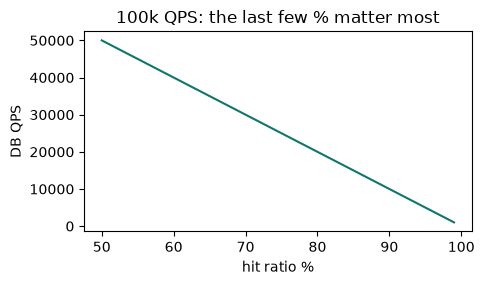

In [2]:
import matplotlib.pyplot as plt


def hit_ratio_curve():
    ratios = [i / 100 for i in range(50, 100)]
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.plot([r * 100 for r in ratios], [100_000 * (1 - r) for r in ratios], color="#0f766e")
    ax.set_xlabel("hit ratio %"); ax.set_ylabel("DB QPS"); ax.set_title("100k QPS: the last few % matter most")


hit_ratio_curve()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q5](#q5), [Q7](#q7), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 2: Eviction policies

*Level: Core*

Memory is limited, so something must go when the cache is full:



| Policy | Evicts | Note |
| --- | --- | --- |
| LRU | least recently used | the default; hash map + linked list → O(1) |
| LFU | least frequently used | keeps long-term favourites; needs ageing |
| FIFO | oldest inserted | simple, ignores reuse |
| Size-aware | by bytes, not count | what real caches do |
| Belady (optimal) | next used farthest in the future | needs the future — a benchmark only |



"Design an LRU cache" is one of the most common interview coding questions: `OrderedDict` in Python, or a dict pointing into a doubly linked list.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
from collections import OrderedDict


def lru_demo():
    cache = OrderedDict()
    for k in ["a", "b", "c", "a", "d"]:
        if k in cache:
            cache.move_to_end(k)
        else:
            if len(cache) == 3:
                print("evict", cache.popitem(last=False)[0])
            cache[k] = 1
        print(k, "->", list(cache))


lru_demo()

a -> ['a']
b -> ['a', 'b']
c -> ['a', 'b', 'c']
a -> ['b', 'c', 'a']
evict b
d -> ['c', 'a', 'd']


**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q10](#q10), [Q11](#q11), [Q17](#q17), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 3: Reading and writing through a cache

*Level: Core*

- **Cache-aside** (lazy loading): the app reads the cache, on a miss reads the DB and fills the cache. On a write, update the DB and **delete** the cache entry. Most common.
- **Read-through**: the cache itself loads from the DB on a miss.
- **Write-through**: every write goes to cache and DB together — always fresh, slower writes.
- **Write-back** (write-behind): write to the cache, flush to the DB later in batches — fast, but data is lost if the cache dies before flushing.



Every cached value has a **TTL** as a safety net: even if an invalidation is missed, staleness is bounded.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q12](#q12), [Q13](#q13), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 4: When caches fail you

*Level: Advanced*

- **Stampede** (thundering herd): a hot key expires and thousands of requests hit the DB at once. Fix: single-flight (one loader per key), serve stale while one request refreshes, refresh ahead of expiry.
- **Synchronised expiry**: keys loaded together expire together. Fix: add random jitter to TTLs.
- **Penetration**: requests for ids that don't exist always miss. Fix: cache "not found" briefly, or a Bloom filter.
- **Hot keys**: one key overloads one cache node. Fix: replicate it, or add a small local cache.
- **Low hit ratio from bad keys**: the same content under many URLs. Fix: normalise the cache key.

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q3](#q3), [Q19](#q19), [Q4](#q4), [Q6](#q6), [Q15](#q15), [Q18](#q18). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [4]:
from collections import Counter, OrderedDict, defaultdict


<a id="q1"></a>
### Q1. A Cache With Expiry

🟢 Warm-up · *TTL*

Process operations `('set', t, key, value, ttl)` and `('get', t, key)`. A value expires once t ≥ set time + ttl. Return the results of the gets (None when missing or expired).

**Examples**

- `ops = [('set', 0, 'price', 100, 10), ('get', 5, 'price'), ('get', 10, 'price'), ('set', 12, 'price', 120, 10), ('get', 15, 'price'), ('get', 15, 'stock')]` → `[100, None, 120, None]`

In [ ]:
def ttl_cache(ops):
    """
    Process operations ('set', t, key, value, ttl) and ('get', t, key). A value
    expires once t ≥ set time + ttl. Return the results of the gets (None when
    missing or expired).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ttl_cache, [
    (([('set', 0, 'price', 100, 10), ('get', 5, 'price'), ('get', 10, 'price'), ('set', 12, 'price', 120, 10), ('get', 15, 'price'), ('get', 15, 'stock')],), [100, None, 120, None]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dict of (value, expires\_at) with if-checks.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with a conditional expression on the lookup.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A dict of (value, expires\_at) with if-checks.

```python
def ttl_cache(ops):
    store, out = {}, []
    for op in ops:
        if op[0] == "set":
            _, t, k, v, ttl = op
            store[k] = (v, t + ttl)
        else:
            _, t, k = op
            if k in store and t < store[k][1]:
                out.append(store[k][0])
            else:
                out.append(None)
    return out
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with a conditional expression on the lookup.

```python
def ttl_cache(ops):
    store, out = {}, []
    for op in ops:
        if op[0] == "set":
            store[op[2]] = (op[3], op[1] + op[4])
        else:
            v, exp = store.get(op[2], (None, -math.inf))
            out.append(v if op[1] < exp else None)
    return out
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dict of (value, expires\_at) with if-checks. That costs O(n) time and O(k) space."

"I can do better: Same, with a conditional expression on the lookup. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/a-cache-with-expiry)

<a id="q2"></a>
### Q2. What a Hit Ratio Buys You

🟢 Warm-up · *Latency and DB load*

For each hit ratio, return `(average latency ms rounded to 2, DB QPS rounded)` given `qps`, cache latency `cache_ms` and DB latency `db_ms` (a miss pays both).

**Examples**

- `qps_ = 50000, cache_ms = 0.5, db_ms = 8, ratios = [0.0, 0.8, 0.95, 0.99]` → `[(8.5, 50000), (2.1, 10000), (0.9, 2500), (0.58, 500)]`

In [ ]:
def hit_ratio_effect(qps_, cache_ms, db_ms, ratios):
    """
    For each hit ratio, return (average latency ms rounded to 2, DB QPS rounded)
    given qps, cache latency cache_ms and DB latency db_ms (a miss pays both).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hit_ratio_effect, [
    ((50000, 0.5, 8, [0.0, 0.8, 0.95, 0.99]), [(8.5, 50000), (2.1, 10000), (0.9, 2500), (0.58, 500)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop.

```python
def hit_ratio_effect(qps_, cache_ms, db_ms, ratios):
    out = []
    for h in ratios:
        latency = h * cache_ms + (1 - h) * (cache_ms + db_ms)
        out.append((round(latency, 2), round(qps_ * (1 - h))))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def hit_ratio_effect(qps_, cache_ms, db_ms, ratios):
    return [(round(cache_ms + (1 - h) * db_ms, 2), round(qps_ * (1 - h))) for h in ratios]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(n) space."

"I can do better: A comprehension. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/what-a-hit-ratio-buys-you)

<a id="q3"></a>
### Q3. Add Jitter to Expiry Times

🟢 Warm-up · *Avoid synchronized expiry*

Keys were all cached at time 0 with TTL `ttl`; with jitter, key i's TTL becomes ttl + `jitter[i]`. Return `(most keys expiring in the same second without jitter, with jitter)`.

**Examples**

- `ttl = 300, jitter = [0, 12, 45, 3, 30, 59, 12, 27, 50, 8]` → `(10, 2)`

In [ ]:
def jitter_effect(ttl, jitter):
    """
    Keys were all cached at time 0 with TTL ttl; with jitter, key i's TTL
    becomes ttl + jitter[i]. Return (most keys expiring in the same second
    without jitter, with jitter).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(jitter_effect, [
    ((300, [0, 12, 45, 3, 30, 59, 12, 27, 50, 8]), (10, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count expiry seconds in a dict.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter(...).most_common(1)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count expiry seconds in a dict.

```python
def jitter_effect(ttl, jitter):
    without = len(jitter)
    counts = {}
    for j in jitter:
        counts[ttl + j] = counts.get(ttl + j, 0) + 1
    return (without, max(counts.values()))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter(...).most_common(1)`.

```python
def jitter_effect(ttl, jitter):
    return (len(jitter), Counter(ttl + j for j in jitter).most_common(1)[0][1])
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count expiry seconds in a dict. That costs O(n) time and O(n) space."

"I can do better: `Counter(...).most_common(1)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/add-jitter-to-expiry-times)

<a id="q4"></a>
### Q4. Cache the Misses Too

🟢 Warm-up · *Negative caching*

Requests ask for ids; some don't exist (not in `db`). Without negative caching every lookup of a missing id hits the DB; with it, the first 'not found' is cached too. Count DB hits both ways (found values are always cached).

**Examples**

- `requests = ['7', 'x9', '7', 'x9', 'x9', '8', 'x9', '8'], db = {'7', '8'}` → `(6, 3)`

In [ ]:
def negative_cache(requests, db):
    """
    Requests ask for ids; some don't exist (not in db). Without negative caching
    every lookup of a missing id hits the DB; with it, the first 'not found' is
    cached too. Count DB hits both ways (found values are always cached).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(negative_cache, [
    ((['7', 'x9', '7', 'x9', 'x9', '8', 'x9', '8'], {'7', '8'}), (6, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two simulations with sets.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Count distinct ids vs repeated misses.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two simulations with sets.

```python
def negative_cache(requests, db):
    cached, without = set(), 0
    for r in requests:
        if r in cached:
            continue
        without += 1
        if r in db:
            cached.add(r)
    with_neg = len(set(requests))
    return (without, with_neg)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Count distinct ids vs repeated misses.

```python
def negative_cache(requests, db):
    found = {r for r in requests if r in db}
    missing_hits = sum(r not in db for r in requests)
    return (len(found) + missing_hits, len(set(requests)))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two simulations with sets. That costs O(n) time and O(n) space."

"I can do better: Count distinct ids vs repeated misses. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/cache-the-misses-too)

<a id="q5"></a>
### Q5. A Two-Level Cache

🟢 Warm-up · *Local memory + Redis*

Requests first check an in-process cache (hit ratio `h1`, `l1_ms`), then Redis (hit ratio `h2` of what's left, `l2_ms`), then the DB (`db_ms`). Return the average latency in ms (rounded to 3) and the % of requests reaching the DB (rounded to 2).

**Examples**

- `h1 = 0.6, h2 = 0.9, l1_ms = 0.01, l2_ms = 0.5, db_ms = 6.0` → `(0.45, 4.0)`

In [ ]:
def two_level(h1, h2, l1_ms, l2_ms, db_ms):
    """
    Requests first check an in-process cache (hit ratio h1, l1_ms), then Redis
    (hit ratio h2 of what's left, l2_ms), then the DB (db_ms). Return the
    average latency in ms (rounded to 3) and the % of requests reaching the DB
    (rounded to 2).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(two_level, [
    ((0.6, 0.9, 0.01, 0.5, 6.0), (0.45, 4.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add the paths step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One expression per figure.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add the paths step by step.

```python
def two_level(h1, h2, l1_ms, l2_ms, db_ms):
    p_l1 = h1
    p_l2 = (1 - h1) * h2
    p_db = (1 - h1) * (1 - h2)
    latency = p_l1 * l1_ms + p_l2 * (l1_ms + l2_ms) + p_db * (l1_ms + l2_ms + db_ms)
    return (round(latency, 3), round(p_db * 100, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One expression per figure.

```python
def two_level(h1, h2, l1_ms, l2_ms, db_ms):
    miss1, miss2 = 1 - h1, (1 - h1) * (1 - h2)
    return (round(l1_ms + miss1 * l2_ms + miss2 * db_ms, 3), round(miss2 * 100, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add the paths step by step. That costs O(1) time and O(1) space."

"I can do better: One expression per figure. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/a-two-level-cache)

<a id="q6"></a>
### Q6. Find the Hot Keys

🟢 Warm-up · *Skewed traffic*

Return the keys that receive more than `share` of all requests (e.g. a celebrity's profile), most requested first. Hot keys overload one cache node; fix with replicas or a local cache.

**Examples**

- `requests = ['u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u2', 'u2', 'u2', 'u2', 'u2', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4'], share = 0.2` → `['u1', 'u3']`

In [ ]:
def hot_keys(requests, share):
    """
    Return the keys that receive more than share of all requests (e.g. a
    celebrity's profile), most requested first. Hot keys overload one cache
    node; fix with replicas or a local cache.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hot_keys, [
    ((['u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u1', 'u2', 'u2', 'u2', 'u2', 'u2', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u3', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4', 'u4'], 0.2), ['u1', 'u3']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a dict, then filter and sort.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter.most_common`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count in a dict, then filter and sort.

```python
def hot_keys(requests, share):
    counts = {}
    for r in requests:
        counts[r] = counts.get(r, 0) + 1
    hot = [(c, k) for k, c in counts.items() if c / len(requests) > share]
    hot.sort(reverse=True)
    return [k for _, k in hot]
```

**Cost:** O(n + k log k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter.most_common`.

```python
def hot_keys(requests, share):
    return [k for k, c in Counter(requests).most_common() if c / len(requests) > share]
```

**Cost:** O(n + k log k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a dict, then filter and sort. That costs O(n + k log k) time and O(k) space."

"I can do better: `Counter.most_common`. That's O(n + k log k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/find-the-hot-keys)

<a id="q7"></a>
### Q7. How Much Memory Will Redis Need?

🟢 Warm-up · *Sizing a cache cluster*

Store `n` keys of `key_bytes` with values of `value_bytes`, plus `overhead` bytes per entry for the store's own structures. Keep memory under `fill` of each node's `node_gb` GB. Return `(total GB rounded to 1, nodes needed)`.

**Examples**

- `n = 200000000, key_bytes = 30, value_bytes = 500, overhead = 90, node_gb = 64, fill = 0.75` → `(124.0, 3)`

In [ ]:
def redis_size(n, key_bytes, value_bytes, overhead, node_gb, fill):
    """
    Store n keys of key_bytes with values of value_bytes, plus overhead bytes
    per entry for the store's own structures. Keep memory under fill of each
    node's node_gb GB. Return (total GB rounded to 1, nodes needed).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(redis_size, [
    ((200000000, 30, 500, 90, 64, 0.75), (124.0, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply, then ceiling divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same with `math.ceil`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply, then ceiling divide.

```python
def redis_size(n, key_bytes, value_bytes, overhead, node_gb, fill):
    total = n * (key_bytes + value_bytes + overhead) / 1e9
    usable = node_gb * fill
    nodes = 0
    while nodes * usable < total:
        nodes += 1
    return (round(total, 1), nodes)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same with `math.ceil`.

```python
def redis_size(n, key_bytes, value_bytes, overhead, node_gb, fill):
    total = n * (key_bytes + value_bytes + overhead) / 1e9
    return (round(total, 1), math.ceil(total / (node_gb * fill)))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply, then ceiling divide. That costs O(1) time and O(1) space."

"I can do better: Same with `math.ceil`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/how-much-memory-will-redis-need)

<a id="q8"></a>
### Q8. Warm the Cache Before Launch

🟢 Warm-up · *Pre-loading*

Before a big sale, preload the `k` most requested keys from yesterday's log. Return the hit ratio (%) on today's requests that this warm cache would give on its own (before any other fills), rounded to 1.

**Examples**

- `yesterday = ['p1', 'p2', 'p1', 'p3', 'p1', 'p2', 'p4'], today = ['p1', 'p2', 'p5', 'p1', 'p3', 'p1', 'p2', 'p6'], k = 2` → `62.5`

In [ ]:
def warm_cache(yesterday, today, k):
    """
    Before a big sale, preload the k most requested keys from yesterday's log.
    Return the hit ratio (%) on today's requests that this warm cache would give
    on its own (before any other fills), rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(warm_cache, [
    ((['p1', 'p2', 'p1', 'p3', 'p1', 'p2', 'p4'], ['p1', 'p2', 'p5', 'p1', 'p3', 'p1', 'p2', 'p6'], 2), 62.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count yesterday, pick the top k, count today's hits.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter.most_common(k)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count yesterday, pick the top k, count today's hits.

```python
def warm_cache(yesterday, today, k):
    counts = {}
    for r in yesterday:
        counts[r] = counts.get(r, 0) + 1
    top = sorted(counts, key=lambda x: (-counts[x], yesterday.index(x)))[:k]
    hits = 0
    for r in today:
        if r in top:
            hits += 1
    return round(hits / len(today) * 100, 1)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter.most_common(k)`.

```python
def warm_cache(yesterday, today, k):
    warm = {key for key, _ in Counter(yesterday).most_common(k)}
    return round(sum(r in warm for r in today) / len(today) * 100, 1)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count yesterday, pick the top k, count today's hits. That costs O(n log n) time and O(n) space."

"I can do better: `Counter.most_common(k)`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/warm-the-cache-before-launch)

<a id="q9"></a>
### Q9. An LRU Cache

🟡 Interview standard · *Evict the least recently used*

Simulate an LRU cache of `capacity` keys over the `accesses`. Return `(hits, misses, keys left from least to most recent)`.

**Examples**

- `capacity = 3, accesses = ['a', 'b', 'c', 'a', 'd', 'b', 'e', 'a', 'c']` → `(1, 8, ['e', 'a', 'c'])`
- `capacity = 2, accesses = ['x', 'x', 'y', 'x', 'z', 'y']` → `(2, 4, ['z', 'y'])`

In [ ]:
def lru(capacity, accesses):
    """
    Simulate an LRU cache of capacity keys over the accesses. Return (hits,
    misses, keys left from least to most recent).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lru, [
    ((3, ['a', 'b', 'c', 'a', 'd', 'b', 'e', 'a', 'c']), (1, 8, ['e', 'a', 'c'])),
    ((2, ['x', 'x', 'y', 'x', 'z', 'y']), (2, 4, ['z', 'y'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list ordered by recency: remove and re-append on each access (O(n) per access).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`OrderedDict.move_to_end` and `popitem(last=False)` make every step O(1).

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A list ordered by recency: remove and re-append on each access (O(n) per access).

```python
def lru(capacity, accesses):
    order, hits, misses = [], 0, 0
    for k in accesses:
        if k in order:
            hits += 1
            order.remove(k)
        else:
            misses += 1
            if len(order) == capacity:
                order.pop(0)
        order.append(k)
    return (hits, misses, order)
```

**Cost:** O(a · c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `OrderedDict.move_to_end` and `popitem(last=False)` make every step O(1).

```python
def lru(capacity, accesses):
    cache, hits = OrderedDict(), 0
    for k in accesses:
        if k in cache:
            hits += 1
            cache.move_to_end(k)
        else:
            if len(cache) == capacity:
                cache.popitem(last=False)
            cache[k] = True
    return (hits, len(accesses) - hits, list(cache))
```

**Cost:** O(a) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list ordered by recency: remove and re-append on each access (O(n) per access). That costs O(a · c) time and O(c) space."

"I can do better: `OrderedDict.move_to_end` and `popitem(last=False)` make every step O(1). That's O(a) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/an-lru-cache)

<a id="q10"></a>
### Q10. An LFU Cache

🟡 Interview standard · *Evict the least frequently used*

Simulate an LFU cache: on a miss with a full cache, evict the key used the fewest times (ties: the one used least recently). Return the evicted keys in order.

**Examples**

- `capacity = 2, accesses = ['a', 'a', 'b', 'c', 'b', 'b', 'd', 'c']` → `['b', 'c', 'a', 'd']`

In [ ]:
def lfu_evictions(capacity, accesses):
    """
    Simulate an LFU cache: on a miss with a full cache, evict the key used the
    fewest times (ties: the one used least recently). Return the evicted keys in
    order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lfu_evictions, [
    ((2, ['a', 'a', 'b', 'c', 'b', 'b', 'd', 'c']), ['b', 'c', 'a', 'd']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track counts and last-use times; scan for the victim.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`min` with a (count, last\_used) key.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Track counts and last-use times; scan for the victim.

```python
def lfu_evictions(capacity, accesses):
    count, last, evicted = {}, {}, []
    for t, k in enumerate(accesses):
        if k not in count and len(count) == capacity:
            victim = None
            for key in count:
                if victim is None or count[key] < count[victim] or (count[key] == count[victim] and last[key] < last[victim]):
                    victim = key
            del count[victim]
            del last[victim]
            evicted.append(victim)
        count[k] = count.get(k, 0) + 1
        last[k] = t
    return evicted
```

**Cost:** O(a · c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `min` with a (count, last\_used) key.

```python
def lfu_evictions(capacity, accesses):
    count, last, evicted = {}, {}, []
    for t, k in enumerate(accesses):
        if k not in count and len(count) == capacity:
            victim = min(count, key=lambda x: (count[x], last[x]))
            del count[victim], last[victim]
            evicted.append(victim)
        count[k], last[k] = count.get(k, 0) + 1, t
    return evicted
```

**Cost:** O(a · c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track counts and last-use times; scan for the victim. That costs O(a · c) time and O(c) space."

"I can do better: `min` with a (count, last\_used) key. That's O(a · c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/an-lfu-cache)

<a id="q11"></a>
### Q11. FIFO vs LRU

🟡 Interview standard · *Policy matters*

Compare hit ratios (%) of FIFO (evict the oldest inserted) and LRU on the same access pattern and capacity. Round to 1.

**Examples**

- `capacity = 3, accesses = ['home', 'a', 'home', 'b', 'home', 'c', 'home', 'd', 'home', 'a']` → `(30.0, 40.0)`

In [ ]:
def fifo_vs_lru(capacity, accesses):
    """
    Compare hit ratios (%) of FIFO (evict the oldest inserted) and LRU on the
    same access pattern and capacity. Round to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fifo_vs_lru, [
    ((3, ['home', 'a', 'home', 'b', 'home', 'c', 'home', 'd', 'home', 'a']), (30.0, 40.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two list-based simulations.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A deque for FIFO and an OrderedDict for LRU.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two list-based simulations.

```python
def fifo_vs_lru(capacity, accesses):
    fifo, f_hits = [], 0
    for k in accesses:
        if k in fifo:
            f_hits += 1
        else:
            if len(fifo) == capacity:
                fifo.pop(0)
            fifo.append(k)
    lru_list, l_hits = [], 0
    for k in accesses:
        if k in lru_list:
            l_hits += 1
            lru_list.remove(k)
        elif len(lru_list) == capacity:
            lru_list.pop(0)
        lru_list.append(k)
    n = len(accesses)
    return (round(f_hits / n * 100, 1), round(l_hits / n * 100, 1))
```

**Cost:** O(a · c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A deque for FIFO and an OrderedDict for LRU.

```python
def fifo_vs_lru(capacity, accesses):
    from collections import deque
    fifo, f_hits = deque(), 0
    for k in accesses:
        if k in fifo:
            f_hits += 1
        else:
            if len(fifo) == capacity:
                fifo.popleft()
            fifo.append(k)
    cache, l_hits = OrderedDict(), 0
    for k in accesses:
        if k in cache:
            l_hits += 1
            cache.move_to_end(k)
        else:
            if len(cache) == capacity:
                cache.popitem(last=False)
            cache[k] = 1
    n = len(accesses)
    return (round(f_hits / n * 100, 1), round(l_hits / n * 100, 1))
```

**Cost:** O(a) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two list-based simulations. That costs O(a · c) time and O(c) space."

"I can do better: A deque for FIFO and an OrderedDict for LRU. That's O(a) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/fifo-vs-lru)

<a id="q12"></a>
### Q12. Cache-Aside and the Stale Read

🟡 Interview standard · *Forgetting to invalidate*

Reads use cache-aside (check cache, else read DB and fill the cache). Writes update the DB, and also delete the cache entry only if `invalidate` is True. Return `(DB reads, reads that returned a stale value)`.

**Examples**

- `ops = [('r', 'x'), ('r', 'x'), ('w', 'x', 2), ('r', 'x'), ('r', 'y'), ('w', 'y', 5), ('r', 'y')], db = {'x': 1, 'y': 9}, invalidate = False` → `(2, 2)`
- `ops = [('r', 'x'), ('r', 'x'), ('w', 'x', 2), ('r', 'x'), ('r', 'y'), ('w', 'y', 5), ('r', 'y')], db = {'x': 1, 'y': 9}, invalidate = True` → `(4, 0)`

In [ ]:
def cache_aside(ops, db, invalidate):
    """
    Reads use cache-aside (check cache, else read DB and fill the cache). Writes
    update the DB, and also delete the cache entry only if invalidate is True.
    Return (DB reads, reads that returned a stale value).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cache_aside, [
    (([('r', 'x'), ('r', 'x'), ('w', 'x', 2), ('r', 'x'), ('r', 'y'), ('w', 'y', 5), ('r', 'y')], {'x': 1, 'y': 9}, False), (2, 2)),
    (([('r', 'x'), ('r', 'x'), ('w', 'x', 2), ('r', 'x'), ('r', 'y'), ('w', 'y', 5), ('r', 'y')], {'x': 1, 'y': 9}, True), (4, 0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two dicts and if-statements.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same with `dict.pop` for the delete.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two dicts and if-statements.

```python
def cache_aside(ops, db, invalidate):
    db, cache = dict(db), {}
    db_reads = stale = 0
    for op in ops:
        if op[0] == "r":
            k = op[1]
            if k in cache:
                value = cache[k]
            else:
                db_reads += 1
                value = db[k]
                cache[k] = value
            if value != db[k]:
                stale += 1
        else:
            db[op[1]] = op[2]
            if invalidate and op[1] in cache:
                del cache[op[1]]
    return (db_reads, stale)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same with `dict.pop` for the delete.

```python
def cache_aside(ops, db, invalidate):
    db, cache, db_reads, stale = dict(db), {}, 0, 0
    for op in ops:
        if op[0] == "w":
            db[op[1]] = op[2]
            if invalidate:
                cache.pop(op[1], None)
            continue
        if op[1] not in cache:
            db_reads += 1
            cache[op[1]] = db[op[1]]
        stale += cache[op[1]] != db[op[1]]
    return (db_reads, stale)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two dicts and if-statements. That costs O(n) time and O(k) space."

"I can do better: Same with `dict.pop` for the delete. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/cache-aside-and-the-stale-read)

<a id="q13"></a>
### Q13. Write-Through or Write-Back?

🟡 Interview standard · *Counting database writes*

A cache of unlimited size receives writes `(key, value)`. Write-through writes every update to the DB immediately. Write-back only marks the key dirty and writes the latest value when `flush` happens at the given write indexes (after that write) and at the end. Return `(DB writes write-through, DB writes write-back)`.

**Examples**

- `writes = [('a', 1), ('a', 2), ('b', 1), ('a', 3), ('b', 2), ('a', 4)], flush_at = [2]` → `(6, 4)`

In [ ]:
def write_policies(writes, flush_at):
    """
    A cache of unlimited size receives writes (key, value). Write-through writes
    every update to the DB immediately. Write-back only marks the key dirty and
    writes the latest value when flush happens at the given write indexes (after
    that write) and at the end. Return (DB writes write-through, DB writes
    write-back).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(write_policies, [
    (([('a', 1), ('a', 2), ('b', 1), ('a', 3), ('b', 2), ('a', 4)], [2]), (6, 4)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count each write; track a dirty set and flush it.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with set operations.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count each write; track a dirty set and flush it.

```python
def write_policies(writes, flush_at):
    through = len(writes)
    dirty, back = set(), 0
    for i, (k, v) in enumerate(writes):
        dirty.add(k)
        if i in flush_at:
            back += len(dirty)
            dirty = set()
    back += len(dirty)
    return (through, back)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with set operations.

```python
def write_policies(writes, flush_at):
    dirty, back = set(), 0
    for i, (k, _) in enumerate(writes):
        dirty.add(k)
        if i in flush_at:
            back, dirty = back + len(dirty), set()
    return (len(writes), back + len(dirty))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count each write; track a dirty set and flush it. That costs O(n) time and O(k) space."

"I can do better: Same, with set operations. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/write-through-or-write-back)

<a id="q14"></a>
### Q14. Cache Stampede

🟡 Interview standard · *Single-flight*

A popular key expires; requests for it arrive at the given times (ms) and a DB load takes `load_ms`. Without protection, every request that arrives before the cache is refilled goes to the DB. With single-flight, only the first one does and the others wait for it. Return `(DB loads without, with single-flight)`.

**Examples**

- `arrivals = [0, 2, 3, 5, 8, 40, 41, 120], load_ms = 30` → `(5, 1)`

In [ ]:
def stampede(arrivals, load_ms):
    """
    A popular key expires; requests for it arrive at the given times (ms) and a
    DB load takes load_ms. Without protection, every request that arrives before
    the cache is refilled goes to the DB. With single-flight, only the first one
    does and the others wait for it. Return (DB loads without, with single-
    flight).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stampede, [
    (([0, 2, 3, 5, 8, 40, 41, 120], 30), (5, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate: track when the cache becomes full again.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same logic: a request misses if it arrives before the refill.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Simulate: track when the cache becomes full again.

```python
def stampede(arrivals, load_ms):
    without = 0
    filled_at = None
    for t in arrivals:
        if filled_at is None or t < filled_at:
            without += 1
            if filled_at is None:
                filled_at = t + load_ms
    with_sf = 1
    return (without, with_sf)
```

**Cost:** O(r) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same logic: a request misses if it arrives before the refill.

```python
def stampede(arrivals, load_ms):
    ready = arrivals[0] + load_ms
    return (sum(t < ready for t in arrivals), 1)
```

**Cost:** O(r) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate: track when the cache becomes full again. That costs O(r) time and O(1) space."

"I can do better: Same logic: a request misses if it arrives before the refill. That's O(r) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/cache-stampede)

<a id="q15"></a>
### Q15. Normalise the Cache Key

🟡 Interview standard · *More hits from the same data*

Build a cache key from a URL: lower-case the host and path, drop tracking parameters in `TRACKING`, sort the remaining parameters. Return the key for each URL and how many distinct keys there are.

**Examples**

- `urls = ['https://Shop.in/Search?q=shoes&page=2&utm_source=mail', 'https://shop.in/search?page=2&q=shoes', 'https://shop.in/search?q=shoes&page=2&gclid=x1', 'https://shop.in/search?q=bags']` → `(['shop.in/search?page=2&q=shoes', 'shop.in/search?page=2&q=shoes', 'shop.in/search?page=2&q=shoes', 'shop.in/search?q=bags'], 2)`

In [ ]:
from urllib.parse import parse_qsl, urlencode, urlparse

TRACKING = {"utm_source", "utm_medium", "utm_campaign", "fbclid", "gclid"}

def cache_keys(urls):
    """
    Build a cache key from a URL: lower-case the host and path, drop tracking
    parameters in TRACKING, sort the remaining parameters. Return the key for
    each URL and how many distinct keys there are.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cache_keys, [
    ((['https://Shop.in/Search?q=shoes&page=2&utm_source=mail', 'https://shop.in/search?page=2&q=shoes', 'https://shop.in/search?q=shoes&page=2&gclid=x1', 'https://shop.in/search?q=bags'],), (['shop.in/search?page=2&q=shoes', 'shop.in/search?page=2&q=shoes', 'shop.in/search?page=2&q=shoes', 'shop.in/search?q=bags'], 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split by hand on '?', '&' and '='.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`urlparse`, `parse_qsl` and `urlencode`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Split by hand on '?', '&' and '='.

```python
def cache_keys(urls):
    keys = []
    for u in urls:
        base, _, query = u.partition("?")
        scheme, _, rest = base.partition("://")
        params = []
        for pair in query.split("&") if query else []:
            k, _, v = pair.partition("=")
            if k not in TRACKING:
                params.append((k, v))
        params.sort()
        key = rest.lower()
        if params:
            key += "?" + "&".join(k + "=" + v for k, v in params)
        keys.append(key)
    return (keys, len(set(keys)))
```

**Cost:** O(n · L) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `urlparse`, `parse_qsl` and `urlencode`.

```python
def cache_keys(urls):
    def key(u):
        p = urlparse(u)
        q = sorted((k, v) for k, v in parse_qsl(p.query) if k not in TRACKING)
        return (p.netloc + p.path).lower() + (f"?{urlencode(q)}" if q else "")
    keys = [key(u) for u in urls]
    return (keys, len(set(keys)))
```

**Cost:** O(n · L) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split by hand on '?', '&' and '='. That costs O(n · L) time and O(n) space."

"I can do better: `urlparse`, `parse_qsl` and `urlencode`. That's O(n · L) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/normalise-the-cache-key)

<a id="q16"></a>
### Q16. What to Invalidate After a Write

🟡 Interview standard · *Tagged invalidation*

Cached pages are tagged with the records they show. When records change, delete every cached key that has any of their tags. Return the keys to delete, sorted.

**Examples**

- `tags = {'page:home': {'product:1', 'product:2', 'banner'}, 'page:p1': {'product:1'}, 'page:p3': {'product:3'}, 'api:cart:7': {'product:2', 'user:7'}}, changed = ['product:2', 'user:9']` → `['api:cart:7', 'page:home']`

In [ ]:
def to_invalidate(tags, changed):
    """
    Cached pages are tagged with the records they show. When records change,
    delete every cached key that has any of their tags. Return the keys to
    delete, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(to_invalidate, [
    (({'page:home': {'product:1', 'product:2', 'banner'}, 'page:p1': {'product:1'}, 'page:p3': {'product:3'}, 'api:cart:7': {'product:2', 'user:7'}}, ['product:2', 'user:9']), ['api:cart:7', 'page:home']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check each key's tags against each changed record.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Build a reverse index tag → keys, then union.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Check each key's tags against each changed record.

```python
def to_invalidate(tags, changed):
    out = []
    for key, ts in tags.items():
        for c in changed:
            if c in ts:
                out.append(key)
                break
    return sorted(out)
```

**Cost:** O(k · t) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Build a reverse index tag → keys, then union.

```python
def to_invalidate(tags, changed):
    reverse = defaultdict(set)
    for key, ts in tags.items():
        for t in ts:
            reverse[t].add(key)
    return sorted(set().union(*(reverse[c] for c in changed)))
```

**Cost:** O(k · t) time, O(k · t) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check each key's tags against each changed record. That costs O(k · t) time and O(k) space."

"I can do better: Build a reverse index tag → keys, then union. That's O(k · t) time and O(k · t) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/what-to-invalidate-after-a-write)

<a id="q17"></a>
### Q17. Evict by Size, Not Count

🟡 Interview standard · *Byte-budgeted LRU*

A cache holds at most `max_bytes`. Items `(key, size)` are accessed in order; on a miss, evict least-recently-used items until the new one fits (skip items bigger than the whole cache). Return the evicted keys in order.

**Examples**

- `max_bytes = 100, items = [('a', 40), ('b', 30), ('a', 40), ('c', 50), ('d', 20), ('b', 30), ('huge', 500)]` → `['b', 'a']`

In [ ]:
def size_lru(max_bytes, items):
    """
    A cache holds at most max_bytes. Items (key, size) are accessed in order; on
    a miss, evict least-recently-used items until the new one fits (skip items
    bigger than the whole cache). Return the evicted keys in order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(size_lru, [
    ((100, [('a', 40), ('b', 30), ('a', 40), ('c', 50), ('d', 20), ('b', 30), ('huge', 500)]), ['b', 'a']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A recency list and a running total.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

An OrderedDict of sizes.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A recency list and a running total.

```python
def size_lru(max_bytes, items):
    order, sizes, used, evicted = [], {}, 0, []
    for k, size in items:
        if k in sizes:
            order.remove(k)
            order.append(k)
            continue
        if size > max_bytes:
            continue
        while used + size > max_bytes:
            victim = order.pop(0)
            used -= sizes.pop(victim)
            evicted.append(victim)
        order.append(k)
        sizes[k] = size
        used += size
    return evicted
```

**Cost:** O(n · c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** An OrderedDict of sizes.

```python
def size_lru(max_bytes, items):
    cache, used, evicted = OrderedDict(), 0, []
    for k, size in items:
        if k in cache:
            cache.move_to_end(k)
        elif size <= max_bytes:
            while used + size > max_bytes:
                victim, vs = cache.popitem(last=False)
                used -= vs
                evicted.append(victim)
            cache[k], used = size, used + size
    return evicted
```

**Cost:** O(n) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A recency list and a running total. That costs O(n · c) time and O(c) space."

"I can do better: An OrderedDict of sizes. That's O(n) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/evict-by-size-not-count)

<a id="q18"></a>
### Q18. Read the Cache-Control Header

🟡 Interview standard · *HTTP caching*

For each response header, decide `(can a shared cache such as a CDN store it?, seconds it stays fresh)`: not storable if it has `no-store` or `private`; freshness is `s-maxage` if present, else `max-age`, else 0. `no-cache` means storable but 0 seconds fresh (always revalidate).

**Examples**

- `headers = ['public, max-age=3600', 'private, max-age=600', 'no-store', 'max-age=60, s-maxage=300', 'no-cache']` → `[(True, 3600), (False, 0), (False, 0), (True, 300), (True, 0)]`

In [ ]:
def cache_control(headers):
    """
    For each response header, decide (can a shared cache such as a CDN store
    it?, seconds it stays fresh): not storable if it has no-store or private;
    freshness is s-maxage if present, else max-age, else 0. no-cache means
    storable but 0 seconds fresh (always revalidate).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cache_control, [
    ((['public, max-age=3600', 'private, max-age=600', 'no-store', 'max-age=60, s-maxage=300', 'no-cache'],), [(True, 3600), (False, 0), (False, 0), (True, 300), (True, 0)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split on commas and check each directive.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Parse each header into a dict of directives once.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Split on commas and check each directive.

```python
def cache_control(headers):
    out = []
    for h in headers:
        parts = [p.strip() for p in h.split(",")]
        storable = "no-store" not in parts and "private" not in parts
        fresh = 0
        s_max = None
        for p in parts:
            if p.startswith("max-age="):
                fresh = int(p.split("=")[1])
            if p.startswith("s-maxage="):
                s_max = int(p.split("=")[1])
        if s_max is not None:
            fresh = s_max
        if "no-cache" in parts:
            fresh = 0
        out.append((storable, fresh if storable else 0))
    return out
```

**Cost:** O(n · d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Parse each header into a dict of directives once.

```python
def cache_control(headers):
    out = []
    for h in headers:
        d = dict((p.strip().split("=") + [None])[:2] for p in h.split(","))
        storable = not ({"no-store", "private"} & d.keys())
        fresh = 0 if "no-cache" in d else int(d.get("s-maxage") or d.get("max-age") or 0)
        out.append((storable, fresh if storable else 0))
    return out
```

**Cost:** O(n · d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split on commas and check each directive. That costs O(n · d) time and O(d) space."

"I can do better: Parse each header into a dict of directives once. That's O(n · d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/read-the-cache-control-header)

<a id="q19"></a>
### Q19. Serve Stale While Revalidating

🟡 Interview standard · *stale-while-revalidate*

A value was fetched at time 0. It is fresh for `ttl` seconds and may be served stale for `swr` more seconds while one background refresh (taking `load` seconds) runs. For each request time, return 'fresh', 'stale' (served old value; starts a refresh if none is running) or 'miss' (too old: the user waits for a fetch). A finished fetch resets the value's age to the time it completed.

**Examples**

- `times = [5, 12, 13, 14, 16, 40, 41, 44], ttl = 10, swr_window = 20, load = 3` → `['fresh', 'stale', 'stale', 'stale', 'fresh', 'stale', 'stale', 'fresh']`

In [ ]:
def swr(times, ttl, swr_window, load):
    """
    A value was fetched at time 0. It is fresh for ttl seconds and may be served
    stale for swr more seconds while one background refresh (taking load
    seconds) runs. For each request time, return 'fresh', 'stale' (served old
    value; starts a refresh if none is running) or 'miss' (too old: the user
    waits for a fetch). A finished fetch resets the value's age to the time it
    completed.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(swr, [
    (([5, 12, 13, 14, 16, 40, 41, 44], 10, 20, 3), ['fresh', 'stale', 'stale', 'stale', 'fresh', 'stale', 'stale', 'fresh']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track fetched\_at and a pending refresh time; update before each request.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same state machine with fewer branches.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Track fetched\_at and a pending refresh time; update before each request.

```python
def swr(times, ttl, swr_window, load):
    fetched, pending, out = 0, None, []
    for t in times:
        if pending is not None and pending <= t:
            fetched, pending = pending, None
        age = t - fetched
        if age < ttl:
            out.append("fresh")
        elif age < ttl + swr_window:
            out.append("stale")
            if pending is None:
                pending = t + load
        else:
            out.append("miss")
            fetched, pending = t + load, None
    return out
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same state machine with fewer branches.

```python
def swr(times, ttl, swr_window, load):
    fetched, pending, out = 0, None, []
    for t in times:
        if pending is not None and pending <= t:
            fetched, pending = pending, None
        age = t - fetched
        state = "fresh" if age < ttl else "stale" if age < ttl + swr_window else "miss"
        out.append(state)
        if state == "stale" and pending is None:
            pending = t + load
        elif state == "miss":
            fetched, pending = t + load, None
    return out
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track fetched\_at and a pending refresh time; update before each request. That costs O(n) time and O(1) space."

"I can do better: Same state machine with fewer branches. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/serve-stale-while-revalidating)

<a id="q20"></a>
### Q20. The Best Possible Eviction (Belady)

🔴 Stretch · *An upper bound for any policy*

The optimal offline policy evicts the key whose next use is farthest in the future (or never). Return `(optimal hits, LRU hits)` for the same capacity — real policies can only approach the optimum because they can't see the future.

**Examples**

- `capacity = 3, accesses = ['a', 'b', 'c', 'd', 'a', 'b', 'e', 'a', 'b', 'c', 'd', 'e']` → `(5, 2)`

In [ ]:
def belady(capacity, accesses):
    """
    The optimal offline policy evicts the key whose next use is farthest in the
    future (or never). Return (optimal hits, LRU hits) for the same capacity —
    real policies can only approach the optimum because they can't see the
    future.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(belady, [
    ((3, ['a', 'b', 'c', 'd', 'a', 'b', 'e', 'a', 'b', 'c', 'd', 'e']), (5, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each eviction, scan ahead to find every key's next use.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Precompute next-use positions with one backward pass.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** For each eviction, scan ahead to find every key's next use.

```python
def belady(capacity, accesses):
    cache, hits = set(), 0
    for i, k in enumerate(accesses):
        if k in cache:
            hits += 1
            continue
        if len(cache) == capacity:
            def next_use(x):
                for j in range(i + 1, len(accesses)):
                    if accesses[j] == x:
                        return j
                return math.inf
            cache.remove(max(sorted(cache), key=next_use))
        cache.add(k)
    order, lru_hits = [], 0
    for k in accesses:
        if k in order:
            lru_hits += 1
            order.remove(k)
        elif len(order) == capacity:
            order.pop(0)
        order.append(k)
    return (hits, lru_hits)
```

**Cost:** O(a² ) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Precompute next-use positions with one backward pass.

```python
def belady(capacity, accesses):
    nxt, seen = [math.inf] * len(accesses), {}
    for i in range(len(accesses) - 1, -1, -1):
        nxt[i] = seen.get(accesses[i], math.inf)
        seen[accesses[i]] = i
    cache, hits = {}, 0
    for i, k in enumerate(accesses):
        if k in cache:
            hits += 1
        elif len(cache) == capacity:
            del cache[max(sorted(cache), key=cache.get)]
        cache[k] = nxt[i]
    od, lru_hits = OrderedDict(), 0
    for k in accesses:
        if k in od:
            lru_hits += 1
            od.move_to_end(k)
        else:
            if len(od) == capacity:
                od.popitem(last=False)
            od[k] = 1
    return (hits, lru_hits)
```

**Cost:** O(a · c) time, O(a) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each eviction, scan ahead to find every key's next use. That costs O(a² ) time and O(c) space."

"I can do better: Precompute next-use positions with one backward pass. That's O(a · c) time and O(a) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/caching/the-best-possible-eviction-belady)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. How do you keep a cache consistent with the database?</b></summary>

Update the database, then delete the cache entry (not update it — two racing updates can leave the old value). Add a TTL as a backstop. For stronger guarantees, invalidate from the database change stream (CDC) so no code path can forget.

</details>

<details>
<summary><b>2. Redis or Memcached?</b></summary>

Memcached is a simple, multi-threaded key-value cache. Redis adds data structures (lists, sorted sets, streams), persistence, replication and Lua scripts — so it also serves as a rate limiter, leaderboard or queue.

</details>

<details>
<summary><b>3. What is a cache stampede and how do you stop it?</b></summary>

Many requests miss the same key at once and all hit the database. Use single-flight locking, serve stale data while one request refreshes, refresh popular keys before they expire, and jitter TTLs.

</details>

<details>
<summary><b>4. What should you not cache?</b></summary>

Data that must be exactly current (balances during payment), data read once, and very large values that evict many useful small ones. Cache what is read often and changes rarely.

</details>

<details>
<summary><b>5. How do you size a cache?</b></summary>

Estimate the working set (hot keys × (key + value + overhead)), leave headroom (fill to ~75%), and measure the hit ratio as you grow — the curve flattens, and beyond that point more memory buys little.

</details>

<details>
<summary><b>6. Why delete instead of update on write?</b></summary>

Deleting is idempotent and avoids races where an older write lands in the cache after a newer one. The next read reloads the current value.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why caches work
- [ ] I can explain: Eviction policies
- [ ] I can explain: Reading and writing through a cache
- [ ] I can explain: When caches fail you

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) What to Invalidate After a Write
- [ ] [Q17](#q17) Evict by Size, Not Count
- [ ] [Q18](#q18) Read the Cache-Control Header
- [ ] [Q19](#q19) Serve Stale While Revalidating
- [ ] [Q20](#q20) The Best Possible Eviction (Belady)

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.